In [1]:
import sys
import csv
from random import shuffle

import numpy as np
import pandas as pd
import requests
import os
from io import StringIO
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import KFold

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [3]:
# feature_list = [
#     'GPS Bearing(deg)',
#     'GPS Altitude(m)',
#     'O2 Lambda Current ER(ratio)',
#     'MAF(l/s)','Speed(km/h)',
#     'GPS Speed(km/h)',
#     'Rpm(u/min)',
#     'O2 Lambda Current(A)',
#     'Throttle Position(%)',
#     'Intake Pressure(kPa)',
#     'GPS Accuracy(%)',
#     'Intake Temperature(c)',
#     'Engine Load(%)',
#     'longitude',
#     'latitude'
# ]
target_value = 'CO2(kg/h)'
feature_list = [
    # 'GPS Bearing(deg)',
    # 'GPS HDOP(precision)',
    # 'GPS Altitude(m)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Consumption(l/h)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)'
]

required_columns = [
    'id',
    'CO2(kg/h)',
    'GPS Bearing(deg)',
    'GPS HDOP(precision)',
    'GPS Altitude(m)',
    'Consumption(l/h)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'time'
]
download_output_dir = 'envirocar_tracks_csv'
original_delimiter = ';'

original_dataset_csv = 'original_dataset.csv'

original_dataset_features = [
'GPS_Speed_Ms','GPS_HDOP','GPS_Bearing','Gx','Gy','Gz','G_Calibrated','OBD_KPL_Average','OBD_Trip_KPL_Average','OBD_Intake_Air_Temp_C','Device_Barometer_M','GPS_Altitude_M','OBD_Engine_Load','OBD_Fuel_Level','GPS_Accuracy_M','OBD_Speed_Km','GPS_Speed_Km','Device_Trip_Dist_Km','OBD_Engine_Coolant_Temp_C','OBD_Engine_RPM','OBD_Adapter_Voltage','OBD_KPL_Instant','OBD_Fuel_Flow_CCmin','Device_Fuel_Remaining','OBD_Ambient_Air_Temp_C','OBD_CO2_gkm_Average',
    #'Device_Cost_Km_Inst',
    'Device_Cost_Km_Trip','OBD_Air_Pedal','Context','Acceleration_kmhs','Reaction_Time','Air_Drag_Force','Speed_RPM_Relation','KPL_Instant'
]
original_dataset_target = 'OBD_CO2_gkm_Instant'

output_dir = '/content/gdrive/MyDrive/imputed_envirocar_data'
output_dir_2 = 'neviro_car_2'
delimiter_value = ','

# output_dir = 'envirocar_tracks_csv'
# delimiter_value = ';'

loss_image_dir = "loss_images"

all_columns_present_id_list = ['661245119828af15e2717fed', '6612450a9828af15e2717c76', '660b61e09828af15e232d0c3', '660b61da9828af15e232ce12', '65eeef0527de036499a72864', '65eeef0a27de036499a72b1b', '65ab9613769a4a5c859dbad6', '65ab9617769a4a5c859dbead', '65ab9626769a4a5c859dc49a', '65ab962a769a4a5c859dc820', '659fa485e4334e110cc91523', '65868308e4334e110cc30bc0', '6586830ce4334e110cc31030', '65868321e4334e110cc31e25', '65868325e4334e110cc32271', '657d6e21e4334e110c29a519', '657d6e27e4334e110c29a61d', '65716543e4334e110c24925a', '655efd4de4334e110cefdb1c', '655efd53e4334e110cefddca', '6520ed349186d0330638b754', '6520ed2f9186d0330638b4ac', '64fc075ade656f7b9eefe24f', '64fc075ade656f7b9eefe364',
                               '64fc0aebde656f7b9ef01ce2', '64b1008ac7e42807e7eabb2f', '64b10090c7e42807e7eabeb2', '649e5fc6c7e42807e751c2ff', '649e5fcac7e42807e751c64f', '64952e3cc7e42807e74b6939', '64952e41c7e42807e74b71d5', '648acd0ac7e42807e7038f32', '6482e20eca0a730aef0f3c67', '6481cd86ca0a730aefddb8f3', '64725ad0ca0a730aef50ed59', '646dc14dca0a730aef443b5f', '646dc174ca0a730aef445de9', '645f34ccca0a730aef36fad2', '645f34cfca0a730aef36fdb6', '644eb8cfca0a730aef197857', '644eb8d1ca0a730aef197b89', '642e5ebcca0a730aeffd3e7a', '642e5ebfca0a730aeffd4239', '642e5ec5ca0a730aeffd4672', '642e5ec8ca0a730aeffd46e3', '642e5ed7ca0a730aeffd53f5', '642e5edaca0a730aeffd54f6', '6412b1f05244bc763ca7d46d',
                               '6412b1f45244bc763ca7d868', '6412b2105244bc763ca7f447', '6412b2145244bc763ca7fb00', '6412b2195244bc763ca7ffdc', '64051f7d5244bc763c94a2fc', '64051f875244bc763c94af3f', '64051fca5244bc763c94e69f', '64077ad15244bc763c98acd2', '64077afa5244bc763c98cdd9', '64077b235244bc763c98d0f6', '64077b265244bc763c98d341', '64077b3f5244bc763c98e4ac', '64077b425244bc763c98e652', '64077b8d5244bc763c98f6a4', '64077b915244bc763c98fca6', '64077b9c5244bc763c990c5a', '64077ba35244bc763c99114a', '64077ba75244bc763c991740', '64077f055244bc763c99491e', '64077f085244bc763c994bb1', '64077f0c5244bc763c99511a', '640782125244bc763c99ade9', '651519169186d03306fb5057', '63a40768ad53a0015a4fe31d',
                               '63a4076bad53a0015a4fe663', '63949b6ead53a0015a096c91', '63948c5cad53a0015a08e2d8', '63948c57ad53a0015a08df35', '63948c1dad53a0015a08b5a1', '63948c1aad53a0015a08b34b', '63948c0aad53a0015a08a51c', '63948c03ad53a0015a08a1e2', '63948bffad53a0015a089f29', '63948b7cad53a0015a084327', '63948b78ad53a0015a084092', '63948aa3ad53a0015a079ee0', '63948925ad53a0015a071369', '63948921ad53a0015a070f6f', '6394891aad53a0015a070a21', '63948917ad53a0015a0706d5', '6394889ead53a0015a06afda', '6394889aad53a0015a06a962', '6394888fad53a0015a0692be', '62ad78db842171051aef8304', '629d9b11842171051acb48e8', '62932392842171051abbeead', '651519f69186d03306fb65d6', '6293239f842171051abbf23e',
                               '629323a7842171051abbf458', '62907ee5842171051ab80ab9', '62907ebf842171051ab7ff00', '62907eef842171051ab821ce', '628542a5842171051acbe8a8', '628542b6842171051acc0024', '628542a4842171051acbe33d', '628542a3842171051acbdf43', '6286a087842171051ace9dd9', '6286a093842171051ace9ff6', '607a2e173b14785a90ce8429', '607a2e1b3b14785a90ce885f', '5eec7aa7d6e3cf256ba3eff9', '5eb7582165b80c5d6be69f22', '5eb7582165b80c5d6be6a142', '5e8b930a65b80c5d6b4d7f2b', '5e42ccb63965f3689459b871', '5e24ca2463c90936dc7b2d94', '5e5e5ecd77e02d42aa94ee1c', '5e1eceab1126d80318bf9f7f', '5e10ec059115b85a123190d0', '5e10ec089115b85a12319686', '5e10ec059115b85a12318e62', '5e08bc845bc8db428964203d',
                               '5e08bc7b5bc8db428964101b', '5e08bc7a5bc8db4289640c77', '5e08bc795bc8db4289640945', '5e08bc795bc8db42896409d5', '5e08bc775bc8db42896406d8', '5e08bc785bc8db4289640875', '5e08bc775bc8db428964066d', '5e6256b977e02d42aa99f3fc', '5de9d7a03bdb691868e76540', '5de0cebf44ea85025c044a15', '5de0cebf44ea85025c044aed', '5ddfd2ba44ea85025c02d828', '5ddfd2bc44ea85025c02dbce', '5de9d7a63bdb691868e77e35', '5de9d7a03bdb691868e765cd', '5ddcdd4a44ea85025cfdf878', '5ddbc67f44ea85025cfc4c10', '5dda4b8144ea856b70e667f0', '5dd7afa244ea856b70e29ecc', '5dd7afa244ea856b70e29e44', '5dd7a23e44ea856b70e28a22', '5dd68af544ea856b70e1471a', '5dd68af244ea856b70e14259', '5dd68aef44ea856b70e140fc',
                               '5dd68aed44ea856b70e13eb5', '5dd68ae944ea856b70e1382b', '5dd68ae544ea856b70e1356b', '5dc985eb44ea856b702dd8c0', '5dc9864c44ea856b702e048a', '5dc986e844ea856b702e3cb5', '5dc9879b44ea856b702e872d', '5dc9c2fe44ea856b7034cbb4', '5dca980744ea856b70363f64', '5dca9b6b44ea856b70364378', '5dcab52c44ea856b70365911', '5dcab5f044ea856b70365f6a', '5dcad90f44ea856b703681ea', '5dcad8d944ea856b70367f91', '5dcad83844ea856b70367d81', '5dcead5644ea856b704d8882', '5dcead4644ea856b704d8428', '5dcbbb1444ea856b7037b264', '5dcead4044ea856b704d8037', '5dcbbb0d44ea856b7037ae6e', '5dcbbb0244ea856b7037ab04', '5dcbb93044ea856b7037a58a', '5dca8b0244ea856b7036389b', '5dca7dce44ea856b70362ef8',
                               '5dcad99b44ea856b70368833', '5dcad96444ea856b70368445', '5dca7e7c44ea856b70363072', '5d757dff44ea853f9f7f62aa', '5d757df644ea853f9f7f6174', '5d746ed344ea853f9f7e5075', '5d5c42ab44ea8550236462ea', '5d59ad7044ea855023610e7e', '5d59ad5b44ea8550236107e0', '5d51f49844ea85502359591b', '5d51f49444ea855023595716', '5d51f48544ea855023594ea6', '5d336ae244ea855023d3745e', '5d336ade44ea855023d372d7', '5d222f4644ea855023c1d0c0', '5d222f2844ea855023c1c8f0', '5d222f2244ea855023c1c7f9', '5d15eef544ea855023b4456f', '5ced330544ea850302918bec', '5ced358044ea850302922200', '5ced359f44ea8503029222ae', '5c95155944ea850302f58228', '5c8c120944ea85030266906a', '5c8c1cc244ea850302669b50',
                               '5c718e9844ea85030245e824', '5c6dba6c44ea85030209b9ae', '5c6dc37c44ea85030209bbc1', '5c684aea44ea850302048409', '5c6844a544ea85030204806f', '5c60075444ea850302fbddf7', '5c5edd0c44ea850302fa9dcd', '5c5edd2744ea850302faa614', '5c28ccc244ea850302c4fd98', '5c28f94644ea850302c50153', '5c26511444ea850302c2d5bf', '5c263bbc44ea850302c2d2b9', '5c0971e344ea8503029b8a83', '5c096abd44ea8503029afd17', '5bfa55dd44ea8503028f0d2e', '5bf9162d44ea8503028df2cf', '5bf90edc44ea8503028df1b2', '5bf8376a44ea8503028ce7af', '5bf831d144ea8503028ce6ee', '5ba9ecf344ea8508426dd940', '5b8847bf44ea8508429306f9', '5b88441b44ea850842930670', '5b76e4f844ea8508423c57d2', '5b74809e44ea8508423177f4',
                               '5b6dd5c644ea85084220335f', '5b6dd3a144ea8508421ffe91', '5b27e0d644ea85091053c8cb', '5b27a84844ea85091053b86f', '5b1cfe7544ea8508ccf04471', '5b1cf8fa44ea8508ccf03cfc', '5ad2479644ea8508c543f14b', '5ad2114844ea8508c543bce1', '5acf80fb44ea8508c53e3cb4', '5a981a8944ea851012d70797', '5a98156544ea851012d68d18', '5a89ceae44ea851012bcc8f5', '5a89cbba44ea851012bcbee4', '5a7f8ea244ea851012b1cae2', '5a7f843d44ea851012b1ca88', '5a7f82d244ea851012b1c4ae', '5a7f564f44ea851012b1b9e7', '5a7f4d4a44ea851012b1b247', '5a625b5a44ea8508ffa54197', '5a61c09544ea85087e7a8d86', '5a61c09344ea85087e7a8bf3', '5a61ae2044ea85087e7a82df', '5a60e7b044ea85087e7a7344', '5a5a5bc944ea85087e6bf7b3',
                               '5a34130f44ea8513da639e87', '5a3412fb44ea8513da639d87', '5a2c14ed268d1b08cd0c27ec', '5a2c14ea268d1b08cd0c1e79', '59cd1eb9268d1b086009a72e', '593165ec268d1b08a4ac122b', '59316592268d1b08a4abfaaa', '59316529268d1b08a4abe33c', '59316569268d1b08a4abee8e', '59249f41268d1b08a49e0507', '59249f30268d1b08a49dfae5', '5915c1f0268d1b08a48d36b2', '5915c1b3268d1b08a48d2a28', '5914078d268d1b08a48bc5fb', '59033b83268d1b08a46be37a', '59033b7b268d1b08a46bd92c', '585198a2e4b0a979d5571317', '5851871de4b0a979d5571212', '57813841e4b0ea2464510f5e', '5760009ee4b091b7fc69d5ca', '5760009ce4b091b7fc69d377', '575bca4ae4b0a69192a28d73', '575bca49e4b0a69192a28be9', '575b17d3e4b0a69192a213b2',
                               '575a63bbe4b0a691929d1f30', '575a63b5e4b0a691929d1c92', '57593b13e4b0a6919296818f', '575860c3e4b0a6919294351a', '575826c1e4b0a6919292205e', '575826bfe4b0a69192921ec8', '5755a4a7e4b0a691928224f9', '57553109e4b0a691927df43a', '573aba1ce4b09078f96804c0', '57337c7fe4b09078f961f02b', '5705764ee4b0b5e237edae2a', '5705764be4b0b5e237edac7f', '57057648e4b0b5e237edab37', '56f120ede4b0b5e237d5756f', '56ee65abe4b0b5e237d32e7f', '56c4766fe4b0df8fa0524f2f', '56c22080e4b0df8fa05006da', '56bbae8ce4b0df8fa021e387', '56bbae8ae4b0df8fa021e284', '56b4dd7de4b0df8fa00669aa', '56b464a2e4b0df8fa005c794', '56b326c0e4b0df8fa0058105', '56b318e8e4b0df8fa0057d11', '56b3170de4b0df8fa0057314',
                               '56b21cede4b0df8fa004baee', '56b21ceae4b0df8fa004b85c', '56af2fb6e4b058e54940a0c2', '56af2fb3e4b058e54940a022', '56a87695e4b000f94dbbc0d5', '56a781bbe4b000f94dbb91d0', '569635d6e4b000f94da7ff63', '569635d1e4b000f94da7fc7c', '567aa2cfe4b000f94d91c837', '567aa2a8e4b000f94d91c72d', '554ce07de4b048885ee0dfa7', '552bff35e4b0bf5f3e46d683', '552bff31e4b0bf5f3e46d3fc', '552418ace4b0bf5f3e43d3ad', '55241876e4b0bf5f3e43a4aa', '553aa4b9e4b080c763779442', '553aa525e4b080c76377a19d', '553aa4b2e4b080c76377917f', '553aa4e9e4b080c763779eda', '55080c87e4b0bf5f3d061b07', '55080c7ee4b0bf5f3d061868', '55241838e4b0bf5f3e437753', '54fda58ae4b0bf5f3cf0d400', '54fda589e4b0bf5f3cf0d0f9',
                               '54fc4853e4b0bf5f3ceb0ad3', '54fc484de4b0bf5f3ceb097c', '54fda585e4b0bf5f3cf0ce0a', '54e30adbe4b0558690c54e8e', '54ec23d6e4b0558690c83df7', '54ec2575e4b0558690c894b3', '54ec2ad2e4b0558690c8e968', '54ec2f1ee4b0558690c939fa', '54ec3350e4b0558690c9809a', '54ec23d1e4b0558690c83b00', '54ec256fe4b0558690c891bc', '54ec2acce4b0558690c8e671', '54ec2f18e4b0558690c93703', '54e30acce4b0558690c54ba8', '54e30a82e4b0558690c54556', '54706aa8e4b094c1030086ea', '53b514bee4b01607fa560ce2', '53b3b0dee4b01607fa556250', '53b3b0f8e4b01607fa5591f5', '53b3b0d6e4b01607fa554637', '53b3b0f0e4b01607fa558784', '53b3b0cde4b01607fa552940', '53b3b0e8e4b01607fa5575d5', '53b3b066e4b01607fa54ed80',
                               '53b2cda1e4b01607fa5454e1', '53b2cd91e4b01607fa544f12', '53b2cd7de4b01607fa544927', '53b2cd6ae4b01607fa54417c', '53b27494e4b01607fa538d1d', '53b5228ee4b01607fa566b78', '53b52282e4b01607fa566469', '53b27449e4b01607fa53736d', '53b52277e4b01607fa565fa6', '53b52266e4b01607fa5656d3', '5371e972e4b05e62155002c4', '5371e96ce4b05e62154ff5ad', '535e0898e4b0976b09bda467', '535e0896e4b0976b09bda210', '5357a002e4b0976b09b935d0', '53579ffce4b0976b09b91b09', '53218b43e4b0c917fe59aa8f', '52f6c62de4b0d8e8c28df6a2', '52eabd02e4b0d8e8c250ca6d', '52e39b02e4b0d8e8c22665c3', '52caf543e4b0f9afbd8d7f8c', '52b19f7ce4b0f9afbd14d773', '52b19f7ae4b0f9afbd14d3a0', '52af4fe9e4b0593cce13cf5d',
                               '52af4fe4e4b0593cce13ccc6', '52af4fe1e4b0593cce13cc37', '528f1a19e4b0ca505ba93418', '528f1a23e4b0ca505ba943d3', '528f1a16e4b0ca505ba92f41', '528f1a20e4b0ca505ba93efc', '52af4fd3e4b0593cce13bfc7', '52af4fd0e4b0593cce13bebc', '528bd8b1e4b08cecc5a6f8bc', '528349ade4b08cecc5a0a0b8', '528349bee4b08cecc5a0b98d']

In [4]:
!pwd

/content


In [5]:
!ls /content/gdrive/MyDrive/imputed_envirocar_data/track_df.csv

/content/gdrive/MyDrive/imputed_envirocar_data/track_df.csv


In [6]:
global_track_df_object = None
sequence_len = 10
ids_list = []
def set_trackdf():
    track_df = pd.read_csv('/content/gdrive/MyDrive/imputed_envirocar_data/track_df.csv')
    global global_track_df_object
    global_track_df_object = track_df
def get_track_ids():
    track_df = global_track_df_object
    unique_ids = track_df['track.id'].unique()
    return unique_ids

In [7]:
def divide_track_ids():
    unique_ids = all_columns_present_id_list
    shuffle(unique_ids)
    total = len(unique_ids)
    print("total unique", total)
    train = int(0.8 * total)
    train_ids = unique_ids[:train]
    test_ids = unique_ids[train:]
    return train_ids, test_ids

def divide_sequences(X, Y):
    n = X.shape[0]
    indices = torch.randperm(n)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]

    train_split = int(0.8 * n)
    validate_split = int(0.1 * n)
    test_split = n - train_split - validate_split

    train_X = shuffled_X[:train_split]
    train_Y = shuffled_Y[:train_split]

    validate_X = shuffled_X[train_split: train_split + validate_split]
    validate_Y = shuffled_Y[train_split: train_split + validate_split]

    test_X = shuffled_X[train_split + validate_split:]
    test_Y = shuffled_Y[train_split + validate_split:]

    return (train_X, train_Y), (test_X, test_Y), (validate_X, validate_Y)

def divide_sequences_cf(X, Y):
    n = X.shape[0]
    indices = torch.randperm(n)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]

    train_split = int(0.9 * n)
    test_split = int(0.1 * n)

    train_X = shuffled_X[:train_split]
    train_Y = shuffled_Y[:train_split]

    test_X = shuffled_X[train_split:]
    test_Y = shuffled_Y[train_split:]

    return (train_X, train_Y), (test_X, test_Y)

def create_sequences(data, target=target_value, features=feature_list, sequence_length=60):
    X, y = [], []
    total = len(data)
    #print("columns", data.columns)
    #print("features",features)
    for i in range(sequence_length, total):
        #if (total-i >= sequence_length): # dropping end sequences
        X.append(data[features].iloc[i-sequence_length:i].values)
        y.append(data[target].iloc[i])
            #print("y", data[target].iloc[i])
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def simple_hash_for_fuel_type(fuelType):
    return hash(fuelType) % 10

In [8]:
def read_data(ids, normalised = False, original=False):
    track_df = global_track_df_object
    excluded_columns = ['id', 'time', 'track.begin', 'track.end']
    track_df = track_df.drop(columns=excluded_columns, errors='ignore')
    X = []
    y = []
    total_count = 0
    big_df = []
    for track_id in ids:
        csv_file = f'{output_dir}/{track_id}.csv'
        df = pd.read_csv(csv_file,delimiter=delimiter_value)
        df['time'] = pd.to_datetime(df['time'])
        tr = track_df[track_df['track.id'] == track_id]
        #print("tr", tr["sensor.engineDisplacement"])
        # df['engineDisplacement'] = tr['sensor.engineDisplacement']
        # df['fuelTypeString'] = tr['sensor.fuelType']
        # df['fuelType'] = df['fuelTypeString'].apply(lambda x: simple_hash_for_fuel_type(x))
        df[target_value].fillna(method='ffill', inplace=True)
        #df['engineDisplacement'].fillna(method='ffill', inplace=True)
        df.fillna(df.mean(numeric_only=True), inplace=True)
        #print("df.isnull().any()", df.isnull().any())
        big_df.append(df)
        #print("df.decribe", df.describe())
        #break;
        #print("type", type(df))
        total_count += len(df)
        seq_x, seq_y = create_sequences(df)
        X.append(seq_x)
        y.append(seq_y)
        #
        # print("shape sw", seq.shape)
        # for label, content in df.items():
        #     print(f'label: {label}')
        #     print(f'content: {content}', sep='\n')
        # break;
    print("shapes", len(X), len(y), X[0].shape, y[0].shape)
    single_df = pd.concat(big_df)
    big_X = torch.cat(X)
    big_y = torch.cat(y).unsqueeze(1)

    if (not normalised):
        return big_X, big_y, single_df
    else:
        min_vals_X = big_X.min(dim=0, keepdim=True)[0].min(dim=1, keepdim=True)[0]
        max_vals_X = big_X.max(dim=0, keepdim=True)[0].max(dim=1, keepdim=True)[0]

        min_vals_y = big_y.min(dim=0, keepdim=True)[0]
        max_vals_y = big_y.max(dim=0, keepdim=True)[0]
        normalized_X = (big_X - min_vals_X) / (max_vals_X - min_vals_X)
        normalized_y = (big_y - min_vals_y) / (max_vals_y - min_vals_y)
        #print("single_df", single_df.describe())
        return normalized_X, normalized_y, single_df

def get_columns(df):
    columns = []
    datatype = []
    for column in df:
        columns.append(column)
        datatype.append(df[column].dtype)
    return columns, datatype

def check_columns(df, required_columns):
    return set(required_columns).issubset(df.columns)

In [9]:
import datetime

import matplotlib.pyplot as plt


def plot_loss(train_losses, val_losses, model_name ="GRU"):
    now = datetime.datetime.now()
    timestamp_string = now.strftime("%Y-%m-%d %H:%M:%S")
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Training loss')
    plt.plot(val_losses, label='Validation loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    #plt.savefig(loss_image_dir +"/" +model_name + "_loss_"+timestamp_string+".png")
    plt.show()

def plot_acc(train_accuracies, valid_accuracies, model_name="GRU"):
    now = datetime.datetime.now()
    timestamp_string = now.strftime("%Y-%m-%d %H:%M:%S")
    plt.figure(figsize=(10, 5))
    plt.plot(train_accuracies, label='Training Accuracy')
    plt.plot(valid_accuracies, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    #plt.savefig(loss_image_dir + "/" + model_name + "_accuracy_" + timestamp_string + ".png")
    plt.show()

def plot_pred(pred, true):
    pred = pred.squeeze()
    true = true.squeeze()
    plt.plot(
        pred[-100:], "-o", color="r", label="Predictions", markersize=2
    )
    plt.plot(true[-100:], color="b", label="Actual")
    plt.ylabel("Energy Consumption (MW)")
    plt.title(f"Energy Consumption Prediction")
    plt.legend()
    plt.show()



In [18]:
class CNN_GRU(nn.Module):
    def __init__(self, input_channels, cnn_out_channels, hidden_size, num_layers, device, kernel_size=3, stride=1,
                 padding=1):
        super(CNN_GRU, self).__init__()
        self.device = device
        self.cnn_layers = nn.Sequential(
                nn.Conv1d(input_channels, cnn_out_channels, kernel_size=kernel_size, padding=padding),
                nn.BatchNorm1d(cnn_out_channels),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2, stride=1),
                nn.Conv1d(cnn_out_channels, cnn_out_channels, kernel_size=kernel_size, padding=padding),
                nn.BatchNorm1d(cnn_out_channels),
                nn.ReLU(),
                nn.MaxPool1d(kernel_size=2, stride=1),
                # nn.Conv1d(cnn_out_channels, cnn_out_channels, kernel_size=kernel_size, padding=padding),
                # nn.BatchNorm1d(cnn_out_channels),
                # nn.ReLU(),
                # nn.MaxPool1d(kernel_size=2, stride=1)
        )
        self.gru = nn.GRU(cnn_out_channels, hidden_size, num_layers, batch_first=True,dropout=0.1)
        self.linear = nn.Linear(hidden_size, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x.to(self.device)
        x = x.permute(0, 2, 1)
        x = self.cnn_layers(x)
        # x = self.bn1(x)
        # x = self.relu(x)
        x = x.permute(0, 2, 1)
        out, _ = self.gru(x)
        output = self.linear(self.relu(out[:, -1, :]))

        return output
class GRU(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, device):
        super(GRU, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1)
        self.device=device

    def forward(self, x):
        x.to(self.device)
        out, _ = self.gru(x)
        out = self.linear(out[:, -1, :])
        out = out.to(self.device)
        return out

class GRUModel():
    def __init__(self, input_size, hidden_size=64, num_layers=2, lr=0.0001, batch_size=64, iteration_name="", cnn=False,cnn_ol=64, reg=1e-5, epochs=20):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.device = torch.device('mps' if torch.backends.mps.is_available() else self.device)
        if(cnn):
            self.model = CNN_GRU(input_size,cnn_ol, hidden_size, num_layers, self.device).to(self.device)
        else:
            self.model = GRU(input_size, hidden_size, num_layers,self.device).to(self.device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr, weight_decay=reg)
        self.criterion = nn.MSELoss()
        self.train_losses = []
        self.val_losses = []
        self.train_accuracy = []
        self.val_accuracy = []
        self.final_accuracy = 0
        self.name = "GRU/" + iteration_name
        self.batch_size = batch_size
        self.epochs = epochs
        self.predictions = []
        self.true_values = []

    def get_dataloader_obj(self, X,y, shuffle=True, dropLast=True):
        X = X.to(self.device)
        y = y.to(self.device)
        dataset = torch.utils.data.TensorDataset(X, y)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle, drop_last=dropLast)
        return dataloader

    def train(self, dataloader, epoch):
        self.model.train()
        ind = 0
        train_loss = 0
        for inputs, labels in dataloader:
            self.optimizer.zero_grad()
            #print("self.device", self.device)
            inputs = inputs.to(self.device)
            labels = labels.to(self.device)
            #print("inputs", inputs)
            #print("device:", inputs.device, labels.device)
            outputs = self.model(inputs)
            loss = self.criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            #print(f'Ind {ind + 1}, Loss: {loss.item()}')
            self.optimizer.step()
            ind += 1
            train_loss += loss.item() #* inputs.size(0)
        print(f' Train Epoch {epoch + 1}, Loss: {loss.item()}')
        train_loss /= len(dataloader.dataset)
        self.train_losses.append(train_loss)

    def validate(self, dataloader, epoch):
        #print("len(dataloader.dataset)",len(dataloader.dataset))
        self.model.eval()
        val_loss = 0
        device = self.device
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, labels)
                val_loss += loss.item()# * inputs.size(0)
            print(f' Validate Epoch {epoch + 1}, Loss: {loss.item()}')
        val_loss /= len(dataloader.dataset)
        self.val_losses.append(val_loss)

    def test(self, dataloader, tolerance =0.2):
        self.model.eval()
        total_mse = 0
        total = 0
        total_within_tol = 0
        device = self.device
        all_outputs = []
        target_labels = []
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                all_outputs.append(outputs.cpu().detach().numpy())
                target_labels.append(labels.cpu().detach().numpy())

                #print("outputs shape", outputs)
                mse = nn.functional.mse_loss(outputs, labels, reduction='sum')
                total_mse += mse.item()

                # Calculate how many predictions are within the tolerance range
                within_tolerance = torch.abs(outputs - labels) <= tolerance * torch.abs(labels)
                total_within_tol += within_tolerance.sum().item()
                total += labels.size(0)

            rmse = np.sqrt(total_mse / total)
            accuracy = total_within_tol / total
            self.predictions = np.concatenate(all_outputs)
            self.true_values = np.concatenate(target_labels)
            return accuracy, rmse


    def plot_analysis(self):
        print("trainloss", self.train_losses)
        print("val loss", self.val_losses)
        plot_loss(self.train_losses,self.val_losses,self.name)
        plot_pred(self.predictions, self.true_values)

        #plot_acc(self.train_accuracy, self.val_accuracy, self.name)

    def run_model(self, train, test, valid):
        (train_x,train_y) = train
        (test_x, test_y) = test
        (valid_x, valid_y) = valid

        train_dataloader = self.get_dataloader_obj(train_x, train_y, True)
        valid_dataloader = self.get_dataloader_obj(valid_x, valid_y, False)
        test_dataloader = self.get_dataloader_obj(test_x, test_y, False)

        for epoch in range(self.epochs):
            self.train(train_dataloader, epoch)
            self.validate(valid_dataloader, epoch)
            # self.train_accuracy.append(self.test(train_dataloader)[0])
            # self.val_accuracy.append(self.test(valid_dataloader)[0])
            # print("accuracy::", self.train_accuracy[-1], self.val_accuracy[-1])
        self.final_accuracy = self.test(test_dataloader)
        print("final accuracy:::::", self.final_accuracy)
        self.plot_analysis()

    def run_model_kf(self, train, test, k):
        (X,Y) = train
        (test_x, test_y) = test

        kf = KFold(n_splits=k, shuffle=True, random_state=42)

          # Initialize lists to store results for each fold
        results = []
        test_dataloader = self.get_dataloader_obj(test_x, test_y, False)
        i=0

        for train_index, test_index in kf.split(X):
        # Split data
          train_x, valid_x = X[train_index], X[test_index]
          train_y, valid_y = Y[train_index], Y[test_index]

          train_dataloader = self.get_dataloader_obj(train_x, train_y, True)
          valid_dataloader = self.get_dataloader_obj(valid_x, valid_y, False)
          print("FOLD::", i+1)


          for epoch in range(self.epochs):
              self.train(train_dataloader, epoch)
              self.validate(valid_dataloader, epoch)
            # self.train_accuracy.append(self.test(train_dataloader)[0])
            # self.val_accuracy.append(self.test(valid_dataloader)[0])
            # print("accuracy::", self.train_accuracy[-1], self.val_accuracy[-1])
          #results.append(self.test(test_dataloader))
          i+=1
        final_acc = self.test(test_dataloader)
        print("final accuracy:::::", final_acc)
        self.plot_analysis()

In [11]:
print("started")
set_trackdf()
it_name = ""
if(len(sys.argv) > 1):
    it_name = sys.argv[1]
print("it", it_name)

X, Y, sdf = read_data(all_columns_present_id_list, True, False)

started


<ipython-input-6-35910b8e0c71>:5: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  track_df = pd.read_csv('/content/gdrive/MyDrive/imputed_envirocar_data/track_df.csv')


it -f


<ipython-input-7-728c88990c21>:59: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:275.)
  return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


shapes 371 371 torch.Size([68, 60, 6]) torch.Size([68])


In [ ]:
## GRU without k fold
#print("singleDF", sdf.describe())
train_seq, test_seq, valid_seq = divide_sequences(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)
gru_model = GRUModel(feature_len, batch_size=1024, num_layers=30, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.00001, reg=1e-6, epochs=30)
gru_model.run_model(train_seq, test_seq, valid_seq)

started


<ipython-input-6-35910b8e0c71>:5: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  track_df = pd.read_csv('/content/gdrive/MyDrive/imputed_envirocar_data/track_df.csv')


it -f


<ipython-input-7-f60d12b11f6b>:42: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:275.)
  return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


shapes 371 371 torch.Size([68, 60, 6]) torch.Size([68])
shape train:: torch.Size([91978, 60, 6]) torch.Size([91978, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])


In [12]:
!nvidia-smi

Fri Apr 26 17:04:06 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA L4                      Off | 00000000:00:03.0 Off |                    0 |
| N/A   41C    P8              16W /  72W |      1MiB / 23034MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [13]:
torch.cuda.is_available()

True

In [19]:
print("started kf")
train_seq, test_seq = divide_sequences_cf(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)


started kf
shape train:: torch.Size([103475, 60, 6]) torch.Size([103475, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])


FOLD:: 1
 Train Epoch 1, Loss: 0.0058845411986112595
 Validate Epoch 1, Loss: 0.005445257760584354
 Train Epoch 2, Loss: 0.004618343897163868
 Validate Epoch 2, Loss: 0.004406322725117207
 Train Epoch 3, Loss: 0.004318285267800093
 Validate Epoch 3, Loss: 0.004378889687359333
 Train Epoch 4, Loss: 0.0037017008289694786
 Validate Epoch 4, Loss: 0.004075180739164352
 Train Epoch 5, Loss: 0.004594523459672928
 Validate Epoch 5, Loss: 0.004001261666417122
 Train Epoch 6, Loss: 0.005425186362117529
 Validate Epoch 6, Loss: 0.004031605087220669
 Train Epoch 7, Loss: 0.004459019750356674
 Validate Epoch 7, Loss: 0.003877475392073393
 Train Epoch 8, Loss: 0.004932589828968048
 Validate Epoch 8, Loss: 0.004021327942609787
 Train Epoch 9, Loss: 0.004190792795270681
 Validate Epoch 9, Loss: 0.003832845017313957
 Train Epoch 10, Loss: 0.003935803193598986
 Validate Epoch 10, Loss: 0.0036837467923760414
 Train Epoch 11, Loss: 0.003963986411690712
 Validate Epoch 11, Loss: 0.0036636763252317905
 Tra

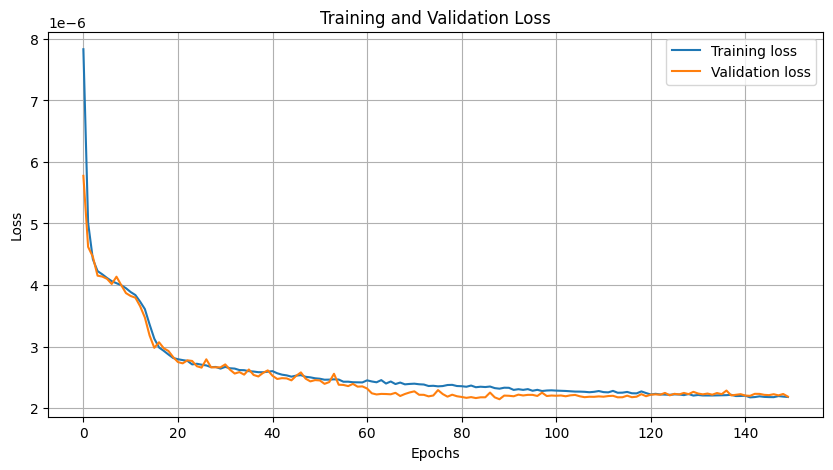

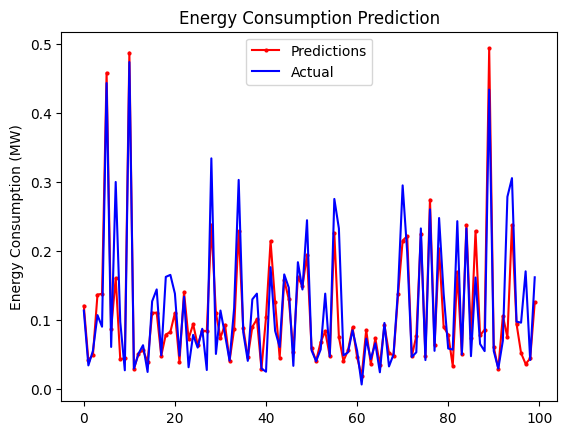

In [20]:
gru_model_kf = GRUModel(feature_len, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.0001, reg=1e-6, epochs=30)
gru_model_kf.run_model_kf(train_seq, test_seq, 5)